## 2026-06-02 Visualising the UMAPs for the Pathway analysis comparisons
### Ovarian Cancer Data only
### Comparing Primary vs Mets vs Ascites vs Healthy in cDC1s, cDC2s and mregDCs

In [1]:
#read in required packages
import os
import tools
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import scanpy as sc
import pandas as pd
import dandelion as ddl

/home/uqlbukat/.local/lib/python3.11/site-packages/nxviz/__init__.py:33: UserWarning: 
nxviz has a new API! Version 0.7.4 onwards, the old class-based API is being
deprecated in favour of a new API focused on advancing a grammar of network
graphics. If your plotting code depends on the old API, please consider
pinning nxviz at version 0.7.4, as the new API will break your old code.

To check out the new API, please head over to the docs at
https://ericmjl.github.io/nxviz/ to learn more. We hope you enjoy using it!

(This deprecation message will go away in version 1.0.)



In [2]:
#read in more packages
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from statannotations.Annotator import Annotator

In [3]:
#read in data
data_all = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad')

In [4]:
#isolate ovarian cancer data
data_oc = data_all[data_all.obs["cancer_with_H"] == "HGSOC"]
data_oc

View of AnnData object with n_obs × n_vars = 9188 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispe

In [5]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines primary vs mets vs ascites vs ascites
data_oc.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              3513
metastatic tumour    3005
primary tumour       2541
healthy               129
Name: count, dtype: int64

In [6]:
data_DC1 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC1"]
data_DC2 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC2"]
data_mregDC = data_oc[data_oc.obs["NR_annotations_simple"] == "mregDC"]

In [7]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines primary vs mets vs ascites vs healthy
data_DC1.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              1025
metastatic tumour     667
primary tumour        628
healthy                28
Name: count, dtype: int64

In [8]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines primary vs mets vs ascites vs healthy
data_DC2.obs["sample_type_major2"].value_counts()

sample_type_major2
ascites              2242
metastatic tumour    1796
primary tumour       1404
healthy                99
Name: count, dtype: int64

In [9]:
#Check the sample type information recorded in the dataset, sample_type_major2 defines primary vs mets vs ascites vs healthy
data_mregDC.obs["sample_type_major2"].value_counts()

sample_type_major2
metastatic tumour    542
primary tumour       509
ascites              246
healthy                2
Name: count, dtype: int64

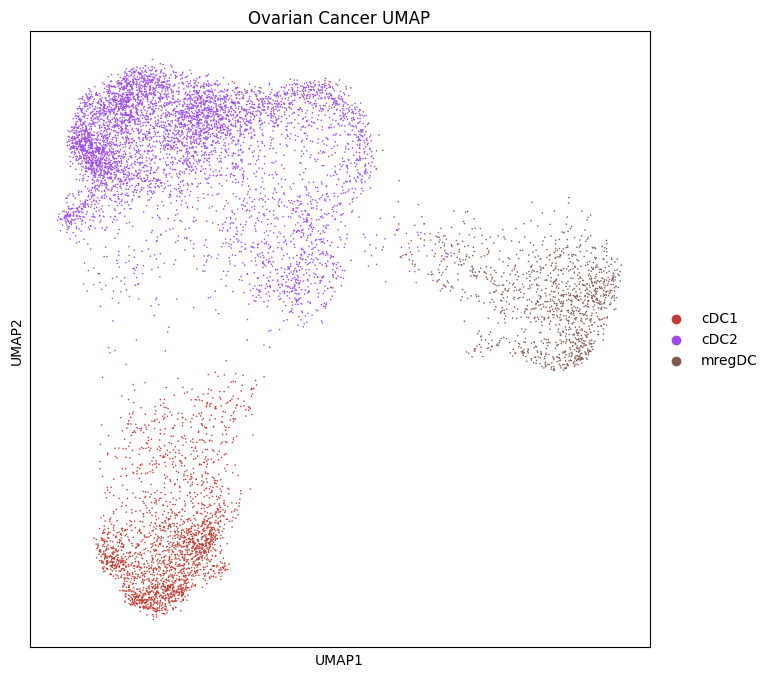

In [12]:
with plt.rc_context({"figure.figsize": (8, 8)}):
    sc.pl.umap(data_oc, color="NR_annotations_simple", size=5, title="Ovarian Cancer UMAP")

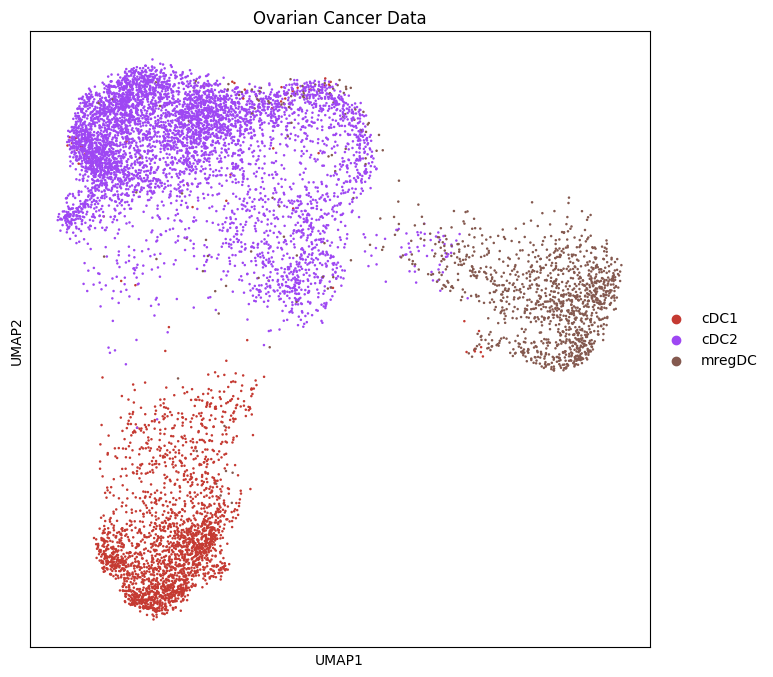

In [27]:
# Plot the UMAP for just this subset
with plt.rc_context({"figure.figsize": (8, 8)}):
 sc.pl.umap(data_oc, color='NR_annotations_simple', title = "Ovarian Cancer Data")

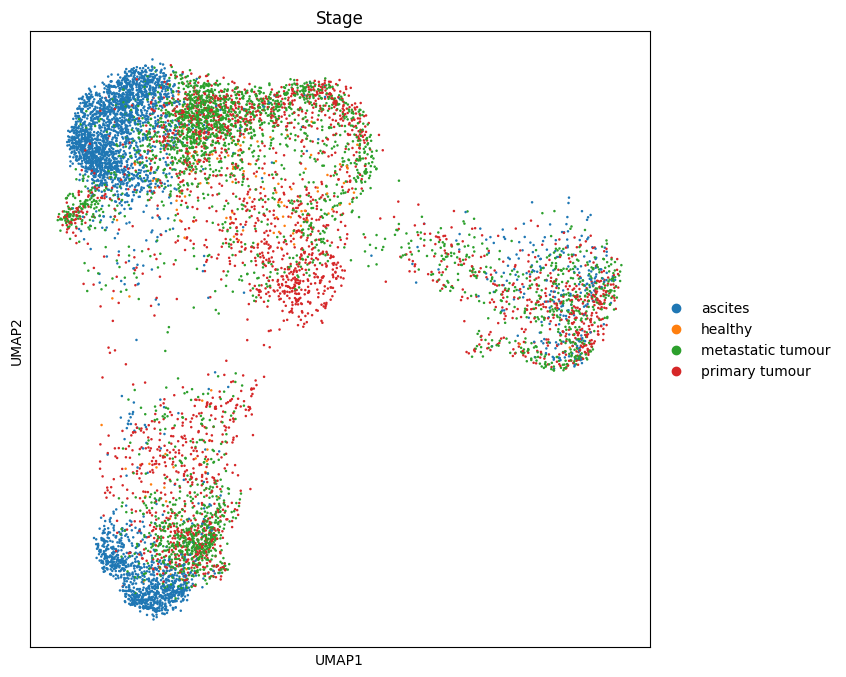

In [28]:
## All ovarian cancer
with plt.rc_context({"figure.figsize": (8, 8)}):
 sc.pl.umap(data_oc, color='sample_type_major2', title= "Stage")

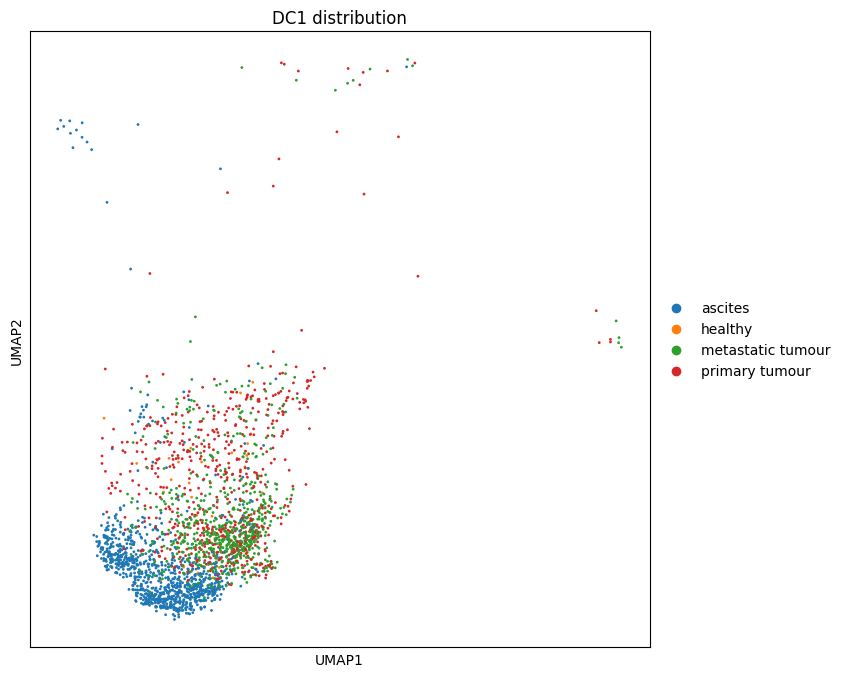

In [29]:
##DC1
# Plot the UMAP for just this subset
with plt.rc_context({"figure.figsize": (8, 8)}):
 sc.pl.umap(data_DC1, color='sample_type_major2', size=16, title= "DC1 distribution")

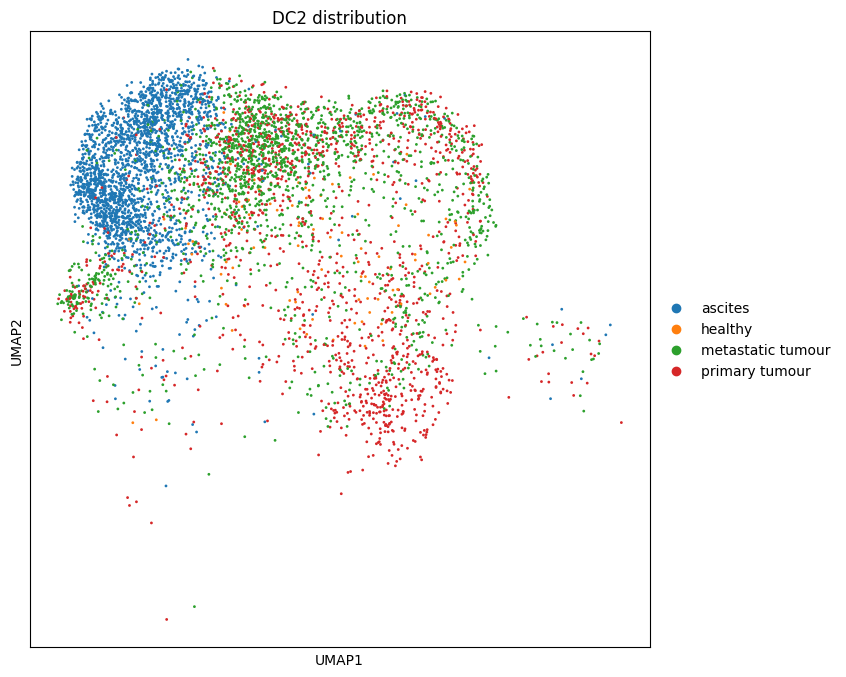

In [30]:
##DC2
# Plot the UMAP for just this subset
with plt.rc_context({"figure.figsize": (8, 8)}):
 sc.pl.umap(data_DC2, color='sample_type_major2', size=16, title= "DC2 distribution")

/home/uqlbukat/.local/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.


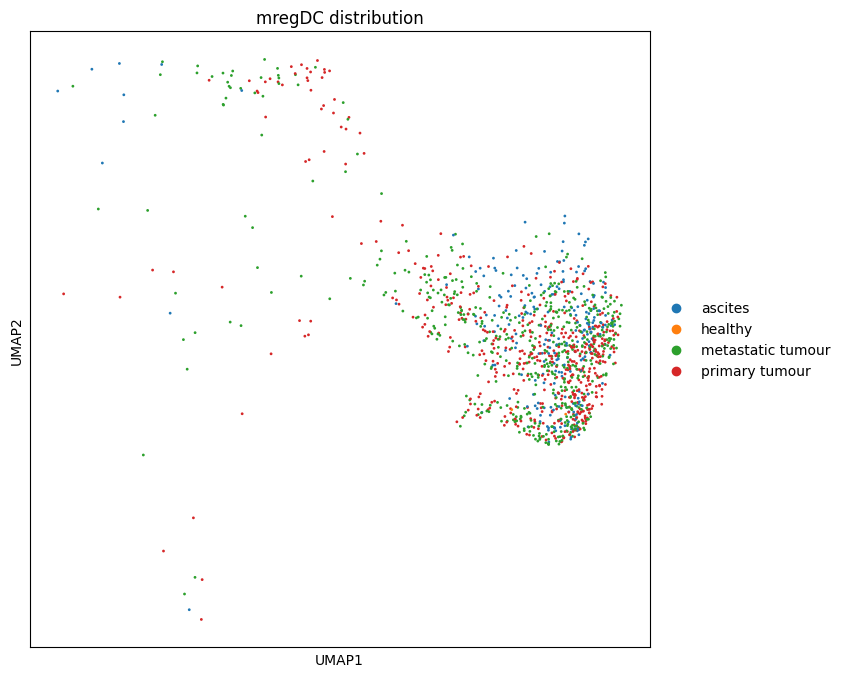

In [31]:
##mregDC
# Plot the UMAP for just this subset
with plt.rc_context({"figure.figsize": (8, 8)}):
 sc.pl.umap(data_mregDC, color='sample_type_major2', size=16, title= "mregDC distribution")

### Draw plot of the HGSOC DC subsets showing the cancer type distribution

In [14]:
data_oc.obs.head()

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
PRJCA005422_EOC2_FS_cell_GTCAAGTTCTTCCTTC,798.0,375.0,Ascites,HGSOC,HGSOC2,PRJCA005422_HGSOC2_AS,6.641604,ascites fluid,ascites,HGSOC,...,Unknown,mregDC,ascites,HGSOC,HGSOC,Treatment naive,0.115363,-0.189154,-0.076538,0.065129
PRJCA005422_EOC1_FS_cell_AAACCTGGTCGGCTCA,11773.0,2471.0,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.089527,ascites fluid,ascites,HGSOC,...,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.617363,-0.265218,-0.154117,-0.014471
PRJCA005422_EOC1_FS_cell_AAACCTGTCATCATTC,15590.0,2937.0,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.411802,ascites fluid,ascites,HGSOC,...,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.757135,-0.231517,-0.100164,-0.001964
PRJCA005422_EOC1_FS_cell_AAAGTAGCATCCGCGA,19965.0,3350.0,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,1.707989,ascites fluid,ascites,HGSOC,...,Unknown,cDC1,ascites,HGSOC,HGSOC,Treatment naive,0.588013,-0.252922,-0.146458,-0.047835
PRJCA005422_EOC1_FS_cell_AAAGTAGTCAAGGCTT,11139.0,2545.0,Ascites,HGSOC,HGSOC1,PRJCA005422_HGSOC1_AS,2.154592,ascites fluid,ascites,HGSOC,...,Unknown,cDC2,ascites,HGSOC,HGSOC,Treatment naive,0.085039,0.058939,-0.059445,0.176612


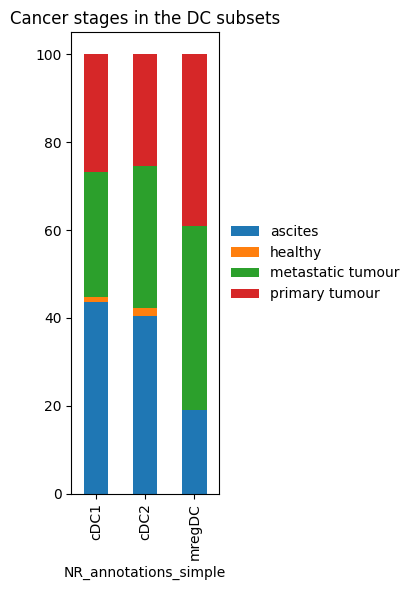

In [20]:
pd.crosstab(data_oc.obs["NR_annotations_simple"], data_oc.obs["sample_type_major2"]).apply(
    lambda r: r / r.sum() * 100, axis=1
).plot.bar(stacked=True, figsize=(4,6))
plt.legend(bbox_to_anchor=(1, 0.5), loc="center left", frameon=False)
plt.title("Cancer stages in the DC subsets")
plt.tight_layout()  
plt.show()

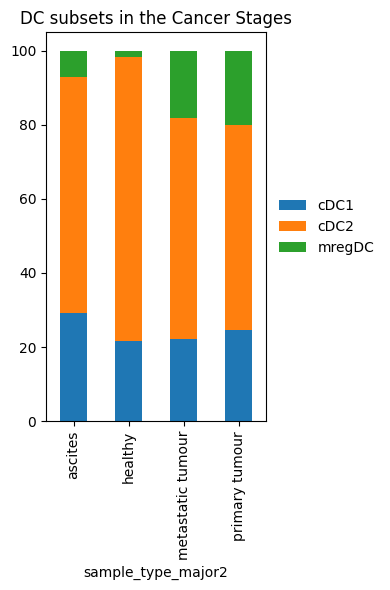

In [18]:
pd.crosstab(data_oc.obs["sample_type_major2"], data_oc.obs["NR_annotations_simple"]).apply(
    lambda r: r / r.sum() * 100, axis=1
).plot.bar(stacked=True, figsize=(4,6))
plt.legend(bbox_to_anchor=(1, 0.5), loc="center left", frameon=False)
plt.title("DC subsets in the Cancer Stages")
plt.tight_layout()  
plt.show()